# 10 - Unsupervised baselines on full BGL

PCA and Isolation Forest on the 20-line window count vectors, with the same settings as notebook 06 (HDFS).

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from sklearn.metrics import roc_auc_score

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

from src.models.unsupervised import IForestDetector, PCADetector, fit_and_score, threshold_sweep, time_split

DOCS = ROOT / "docs"
PROCESSED = ROOT / "data" / "processed"
PERCENTILES = [90, 95, 97.5, 99, 99.5]


def make_models():
    return {"PCA": PCADetector(variance=0.95), "Isolation Forest": IForestDetector(n_estimators=100, random_state=42)}


def split(counts, order_col):
    """Time-ordered 70/30 split; train only on the normal part of the first 70%."""
    event_cols = counts.filter(regex=r"^E\d+$").columns
    train, test = time_split(counts, train_frac=0.7, order_col=order_col)
    return train, test, train.loc[train["Label"] == 0, event_cols].to_numpy(), test[event_cols].to_numpy(), test["Label"].to_numpy()

## Train / test split

The first 70% of windows (by window index) are used for training, keeping only the normal ones, and the last 30% for testing.

In [2]:
counts = pd.read_parquet(PROCESSED / "bgl_counts.parquet")
train, test, X_train, X_test, y_test = split(counts, order_col="window")

print(f"Anomalous windows in train part: {train['Label'].mean():.2%}   in test part: {test['Label'].mean():.2%}")
pd.DataFrame({
    "windows": [len(train), len(X_train), len(test)],
    "anomalous windows": [train["Label"].sum(), 0, y_test.sum()],
}, index=["first 70%", "train (normal only)", "test (last 30%)"])

Anomalous windows in train part: 9.00%   in test part: 7.46%


,windows,anomalous windows
first 70%,166178,14949
train (normal only),151229,0
test (last 30%),71220,5312


## Train and score

PCA uses TF-IDF weighted, zero-mean counts and keeps 95% of the variance. Isolation Forest uses the raw counts.

In [3]:
models = make_models()
scores, auc = {}, {}
for name, model in models.items():
    train_scores, test_scores, fit_s, score_s = fit_and_score(model, X_train, X_test)
    scores[name] = (train_scores, test_scores)
    auc[name] = roc_auc_score(y_test, test_scores)
    print(f"{name:17s} training: {fit_s:6.2f} s   scoring: {score_s:6.2f} s   ROC-AUC: {auc[name]:.3f}")

print(f"PCA components kept: {models['PCA'].pca.n_components_}")

PCA               training:   0.74 s   scoring:   1.26 s   ROC-AUC: 0.923


Isolation Forest  training:   0.26 s   scoring:   0.45 s   ROC-AUC: 0.222
PCA components kept: 59


## Score check

Isolation Forest's ROC-AUC is below 0.5, but the score sign is the same as on HDFS. Most anomalous test windows contain templates that never appear in the normal training windows, and Isolation Forest cannot split on a feature that is always 0 in training (as in notebook 03). PCA sees these templates as reconstruction error, which also causes its false alarms on normal windows with new templates.

In [4]:
unseen = X_train.sum(axis=0) == 0
has_unseen = X_test[:, unseen].sum(axis=1) > 0
print(f"Templates never seen in normal training windows: {unseen.sum()} of {X_train.shape[1]}")
print(f"Isolation Forest ROC-AUC on test windows without such templates: "
      f"{roc_auc_score(y_test[~has_unseen], scores['Isolation Forest'][1][~has_unseen]):.3f}")
pd.crosstab(y_test, has_unseen, rownames=["label"], colnames=["window has an unseen template"])

Templates never seen in normal training windows: 155 of 391
Isolation Forest ROC-AUC on test windows without such templates: 0.554


window has an unseen template,False,True
label,,
0,44596,21312
1,119,5193


## Threshold test

Each threshold is a percentile of the model's scores on the normal training windows.

In [5]:
results = pd.DataFrame([
    row for name, (train_scores, test_scores) in scores.items()
    for row in threshold_sweep(name, train_scores, test_scores, y_test, PERCENTILES)
])

results.round(4).to_csv(DOCS / "bgl_unsupervised_results.csv", index=False)
results.style.format({c: "{:.3f}" for c in ["precision", "recall", "f1", "false_alarm_rate"]}).hide(axis="index")

model,percentile,precision,recall,f1,false_alarm_rate
PCA,90.000000,0.137,0.999,0.240,0.509
PCA,95.000000,0.170,0.998,0.290,0.394
PCA,97.500000,0.182,0.996,0.307,0.362
PCA,99.000000,0.185,0.970,0.311,0.344
PCA,99.500000,0.187,0.955,0.312,0.335
Isolation Forest,90.000000,0.034,0.043,0.038,0.098
Isolation Forest,95.000000,0.038,0.036,0.037,0.075
Isolation Forest,97.500000,0.031,0.016,0.021,0.041
Isolation Forest,99.000000,0.019,0.002,0.004,0.009
Isolation Forest,99.500000,0.018,0.001,0.002,0.005


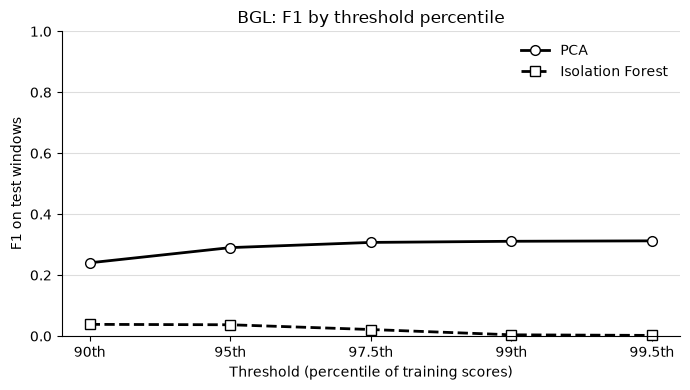

In [6]:
fig, ax = plt.subplots(figsize=(7, 4))
x = range(len(PERCENTILES))  # evenly spaced, since the percentiles are not
styles = {"PCA": dict(linestyle="-", marker="o"), "Isolation Forest": dict(linestyle="--", marker="s")}
for name, style in styles.items():
    f1 = results.loc[results["model"] == name, "f1"]
    ax.plot(x, f1, color="black", linewidth=2, markersize=7, markerfacecolor="white", clip_on=False, label=name, **style)

ax.set_xticks(x, [f"{p:g}th" for p in PERCENTILES])
ax.set_ylim(0, 1)
ax.set_xlabel("Threshold (percentile of training scores)")
ax.set_ylabel("F1 on test windows")
ax.set_title("BGL: F1 by threshold percentile")
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)
ax.yaxis.grid(True, color="#dddddd", linewidth=0.8)
ax.set_axisbelow(True)

fig.tight_layout()
fig.savefig(DOCS / "bgl_unsupervised_f1.png", dpi=150, facecolor="white")
plt.show()

## HDFS vs BGL

Best F1 over the five thresholds, and ROC-AUC. The HDFS F1 comes from `docs/hdfs_unsupervised_results.csv`; its ROC-AUC is not in that file, so it is recomputed here with the same split and settings.

In [7]:
_, _, X_train_h, X_test_h, y_test_h = split(pd.read_parquet(PROCESSED / "hdfs_counts.parquet"), order_col="order")
auc_hdfs = {name: roc_auc_score(y_test_h, m.fit(X_train_h).score(X_test_h)) for name, m in make_models().items()}
best_hdfs = pd.read_csv(DOCS / "hdfs_unsupervised_results.csv").groupby("model")["f1"].max()
best_bgl = results.groupby("model")["f1"].max()

pd.DataFrame({
    "HDFS best F1": best_hdfs, "HDFS ROC-AUC": pd.Series(auc_hdfs),
    "BGL best F1": best_bgl, "BGL ROC-AUC": pd.Series(auc),
}).loc[["PCA", "Isolation Forest"]].round(3)

,HDFS best F1,HDFS ROC-AUC,BGL best F1,BGL ROC-AUC
PCA,0.854,0.961,0.312,0.923
Isolation Forest,0.051,0.685,0.038,0.222


## Check: drift and Isolation Forest misses

Anomaly share in each part, and how the PCA scores of normal windows change from the training period to the test period.

In [8]:
import numpy as np

print(f"Anomalous windows in train part: {train['Label'].mean():.2%}   in test part: {test['Label'].mean():.2%}\n")

pca_train, pca_test = scores["PCA"][0], scores["PCA"][1][y_test == 0]
print(pd.DataFrame({
    "median": [np.median(pca_train), np.median(pca_test)],
    "99th percentile": [np.percentile(pca_train, 99), np.percentile(pca_test, 99)],
}, index=["normal train windows", "normal test windows"]).round(3))

Anomalous windows in train part: 9.00%   in test part: 7.46%

                      median  99th percentile
normal train windows   0.013          1770.66
normal test windows   26.986        368447.31


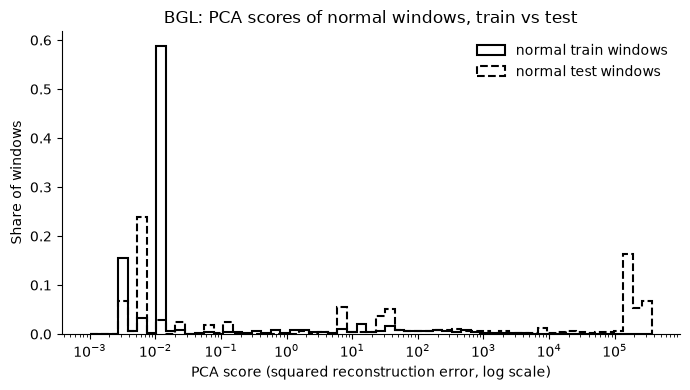

In [9]:
fig, ax = plt.subplots(figsize=(7, 4))
eps = 1e-3  # scores of 0 can't go on a log axis
bins = np.logspace(np.log10(eps), np.log10(max(pca_train.max(), pca_test.max()) + eps), 60)
# weights give the share of windows per bin (density would shrink the wide bins on a log axis)
ax.hist(pca_train + eps, bins=bins, weights=np.full(len(pca_train), 1 / len(pca_train)), histtype="step", color="black", linewidth=1.5, label="normal train windows")
ax.hist(pca_test + eps, bins=bins, weights=np.full(len(pca_test), 1 / len(pca_test)), histtype="step", color="black", linewidth=1.5, linestyle="--", label="normal test windows")

ax.set_xscale("log")
ax.set_xlabel("PCA score (squared reconstruction error, log scale)")
ax.set_ylabel("Share of windows")
ax.set_title("BGL: PCA scores of normal windows, train vs test")
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)

fig.tight_layout()
fig.savefig(DOCS / "bgl_pca_drift.png", dpi=150, facecolor="white")
plt.show()

The 5 anomalous test windows that Isolation Forest scores as most normal (lowest score).

In [10]:
sequences = pd.read_parquet(PROCESSED / "bgl_sequences.parquet").set_index("window")
templates = pd.read_csv(PROCESSED / "bgl_templates.csv").set_index("EventId")["template"]

if_test = scores["Isolation Forest"][1]
anomalous = np.where(y_test == 1)[0]
most_normal = anomalous[np.argsort(if_test[anomalous])[:5]]
for pos in most_normal:
    window = test["window"].iloc[pos]
    seq = sequences.loc[window, "EventSequence"]
    print(f"window {window}  IF score {if_test[pos]:.3f}: {' '.join(seq)}")
    for event in dict.fromkeys(seq):
        print(f"    {event}: {templates[event]}")

single = (X_test[y_test == 1] > 0).sum(axis=1) == 1
print(f"\nAnomalous test windows with only one distinct event: {single.mean():.1%} ({single.sum():,} of {len(single):,})")

window 213648  IF score 0.302: E349 E349 E349 E349 E349 E349 E349 E349 E349 E349 E349 E349 E349 E349 E349 E349 E349 E349 E349 E349
    E349: ciod: Error reading message prefix on CioStream socket to <IP>, <*> <*> <*> <*>
window 213683  IF score 0.302: E345 E345 E349 E345 E349 E345 E345 E345 E345 E345 E345 E345 E345 E349 E345 E349 E345 E345 E349 E345
    E345: ciod: Received signal <NUM>, code=<NUM>, errno=<NUM>, address=<HEX>
    E349: ciod: Error reading message prefix on CioStream socket to <IP>, <*> <*> <*> <*>
window 213682  IF score 0.302: E345 E345 E345 E345 E345 E345 E349 E345 E345 E349 E345 E345 E345 E349 E345 E345 E349 E345 E345 E345
    E345: ciod: Received signal <NUM>, code=<NUM>, errno=<NUM>, address=<HEX>
    E349: ciod: Error reading message prefix on CioStream socket to <IP>, <*> <*> <*> <*>
window 213681  IF score 0.302: E345 E349 E345 E349 E345 E349 E345 E345 E349 E345 E345 E349 E345 E345 E345 E349 E345 E345 E345 E349
    E345: ciod: Received signal <NUM>, code=<NUM>,